# Filtro de celdas inhabitables y variables de entorno

Este notebook corre `src/features.py` sobre las tablas del ETL v2 y responde dos puntos del feedback de la presentación de avance:

- **Celdas inhabitables:** se descartan las celdas que están a más de X metros de una celda poblada (cerros, cordillera, zonas sin uso). X se elige con los datos: el menor valor que conserva al menos el 99% de los supermercados de ambas ciudades.
- **Correlación espacial:** cada celda recibe variables de su entorno (sumas en radios de 500 m y 1 km), porque la demanda de un supermercado está en el área que lo rodea y no solo en su celda.

Produce `data/processed/modelo_<tamaño>m.parquet`, una tabla por tamaño de celda con ambas ciudades y solo las celdas habitables, más los resultados en `resultados/features/`. La corrida toma menos de un minuto y no necesita los datos crudos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from src import features

cfg = features.cargar_config("config.yaml")
procesados = cfg["rutas"]["processed"]
resultados = cfg["rutas"]["resultados_features"]

COLORES = {"stgo": "#2a78d6", "ccp": "#eb6834", "ambas": "#52514e"}
NOMBRES = {k: v["nombre"] for k, v in cfg["ciudades"].items()} | {"ambas": "Ambas ciudades"}
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 1. Corrida completa

In [2]:
r = features.ejecutar(cfg)
x = r["x_m"]
curva, resumen = r["curva"], r["resumen"]

[18:09:43] X elegido con los datos: 750 m; X usado: 750 m


[18:09:46] 125 m: 97,473 celdas habitables (679 supermercados) -> data/processed/modelo_125m.parquet


[18:09:46] 250 m: 24,948 celdas habitables (679 supermercados) -> data/processed/modelo_250m.parquet


[18:09:46] 500 m: 6,604 celdas habitables (679 supermercados) -> data/processed/modelo_500m.parquet


[18:09:46] 1000 m: 1,403 celdas habitables (678 supermercados) -> data/processed/modelo_1000m.parquet


[18:09:47] 250 m desplazada: 24,864 celdas habitables (679 supermercados) -> data/processed/modelo_250m_d125.parquet


[18:09:47] Listo.


## 2. Elección de X

Para cada X candidato se calcula qué parte de los supermercados y de la grilla queda dentro del filtro, en la grilla principal de 250 m. X es el menor candidato que conserva al menos el 99% de los supermercados de ambas ciudades juntas; el mismo X se aplica después a todos los tamaños de celda. Toda la población queda dentro con cualquier X, porque las celdas pobladas están a distancia 0 de sí mismas.

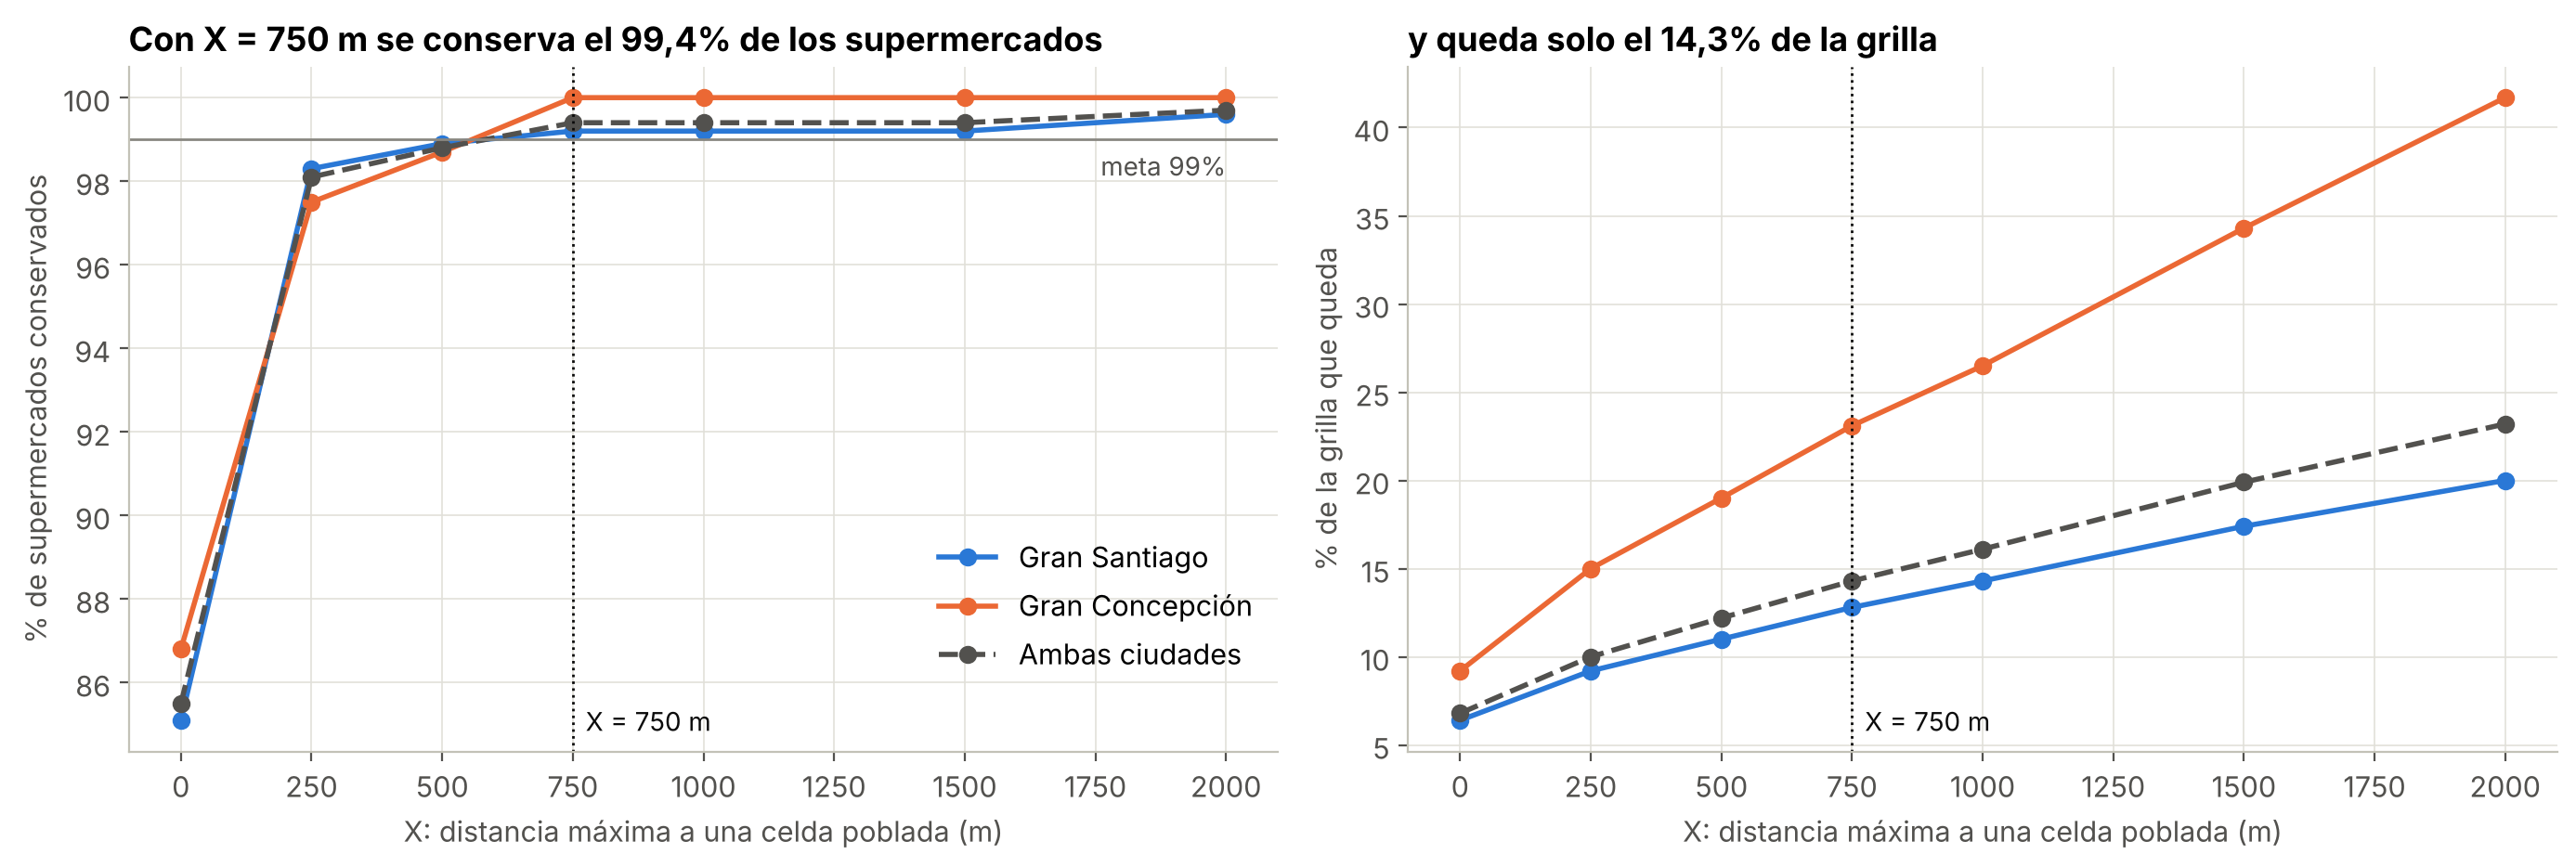

pct_supermercados              pct_celdas              \
ciudad             ambas    ccp  stgo      ambas   ccp  stgo   
x_m                                                            
0                   85.5   86.8  85.1        6.8   9.2   6.4   
250                 98.1   97.5  98.3       10.0  15.0   9.2   
500                 98.8   98.7  98.9       12.2  19.0  11.0   
750                 99.4  100.0  99.2       14.3  23.1  12.8   
1000                99.4  100.0  99.2       16.1  26.5  14.3   
1500                99.4  100.0  99.2       19.9  34.3  17.4   
2000                99.7  100.0  99.6       23.2  41.7  20.0   

       celdas_habitables                    
ciudad             ambas      ccp     stgo  
x_m                                         
0                11902.0   2317.0   9585.0  
250              17430.0   3787.0  13643.0  
500              21198.0   4794.0  16404.0  
750              24948.0   5820.0  19128.0  
1000             28007.0   6683.0  21324.0  
1500             34591.0   8644.0  25947.0  
2000             40342.0  10517.0  29825.0

In [3]:
ambas_x = curva[(curva["ciudad"] == "ambas") & (curva["x_m"] == x)].iloc[0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
for ciudad in ["stgo", "ccp", "ambas"]:
    d = curva[curva["ciudad"] == ciudad]
    estilo = dict(color=COLORES[ciudad], linewidth=2, marker="o", markersize=6,
                  linestyle="--" if ciudad == "ambas" else "-", label=NOMBRES[ciudad])
    a1.plot(d["x_m"], d["pct_supermercados"], **estilo)
    a2.plot(d["x_m"], d["pct_celdas"], **estilo)
meta = 100 * cfg["features"]["filtro_x"]["cobertura_supermercados"]
a1.axhline(meta, color="#898781", linewidth=1)
a1.annotate(f"meta {meta:.0f}%", (curva["x_m"].max(), meta), xytext=(0, -14), textcoords="offset points",
            ha="right", color="#52514e", fontsize=10)
for a in (a1, a2):
    a.axvline(x, color="#0b0b0b", linewidth=1, linestyle=":")
    a.annotate(f"X = {x:.0f} m", (x, a.get_ylim()[0]), xytext=(5, 8), textcoords="offset points", fontsize=10, color="#0b0b0b")
    a.set_xlabel("X: distancia máxima a una celda poblada (m)")
a1.set_ylabel("% de supermercados conservados")
a2.set_ylabel("% de la grilla que queda")
pct = lambda v: f"{v:.1f}".replace(".", ",")
a1.set_title(f"Con X = {x:.0f} m se conserva el {pct(ambas_x['pct_supermercados'])}% de los supermercados")
a2.set_title(f"y queda solo el {pct(ambas_x['pct_celdas'])}% de la grilla")
a1.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.08))
fig.tight_layout()
fig.savefig(f"{resultados}/curva_filtro_x.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

curva.pivot(index="x_m", columns="ciudad", values=["pct_supermercados", "pct_celdas", "celdas_habitables"])

## 3. Qué queda dentro y fuera del filtro (celdas de 250 m)

Gris oscuro: celdas pobladas. Gris claro: celdas sin habitantes pero a X metros o menos de una poblada (quedan dentro). Gris muy claro: celdas descartadas. Las cruces negras son los supermercados que quedan fuera del filtro.

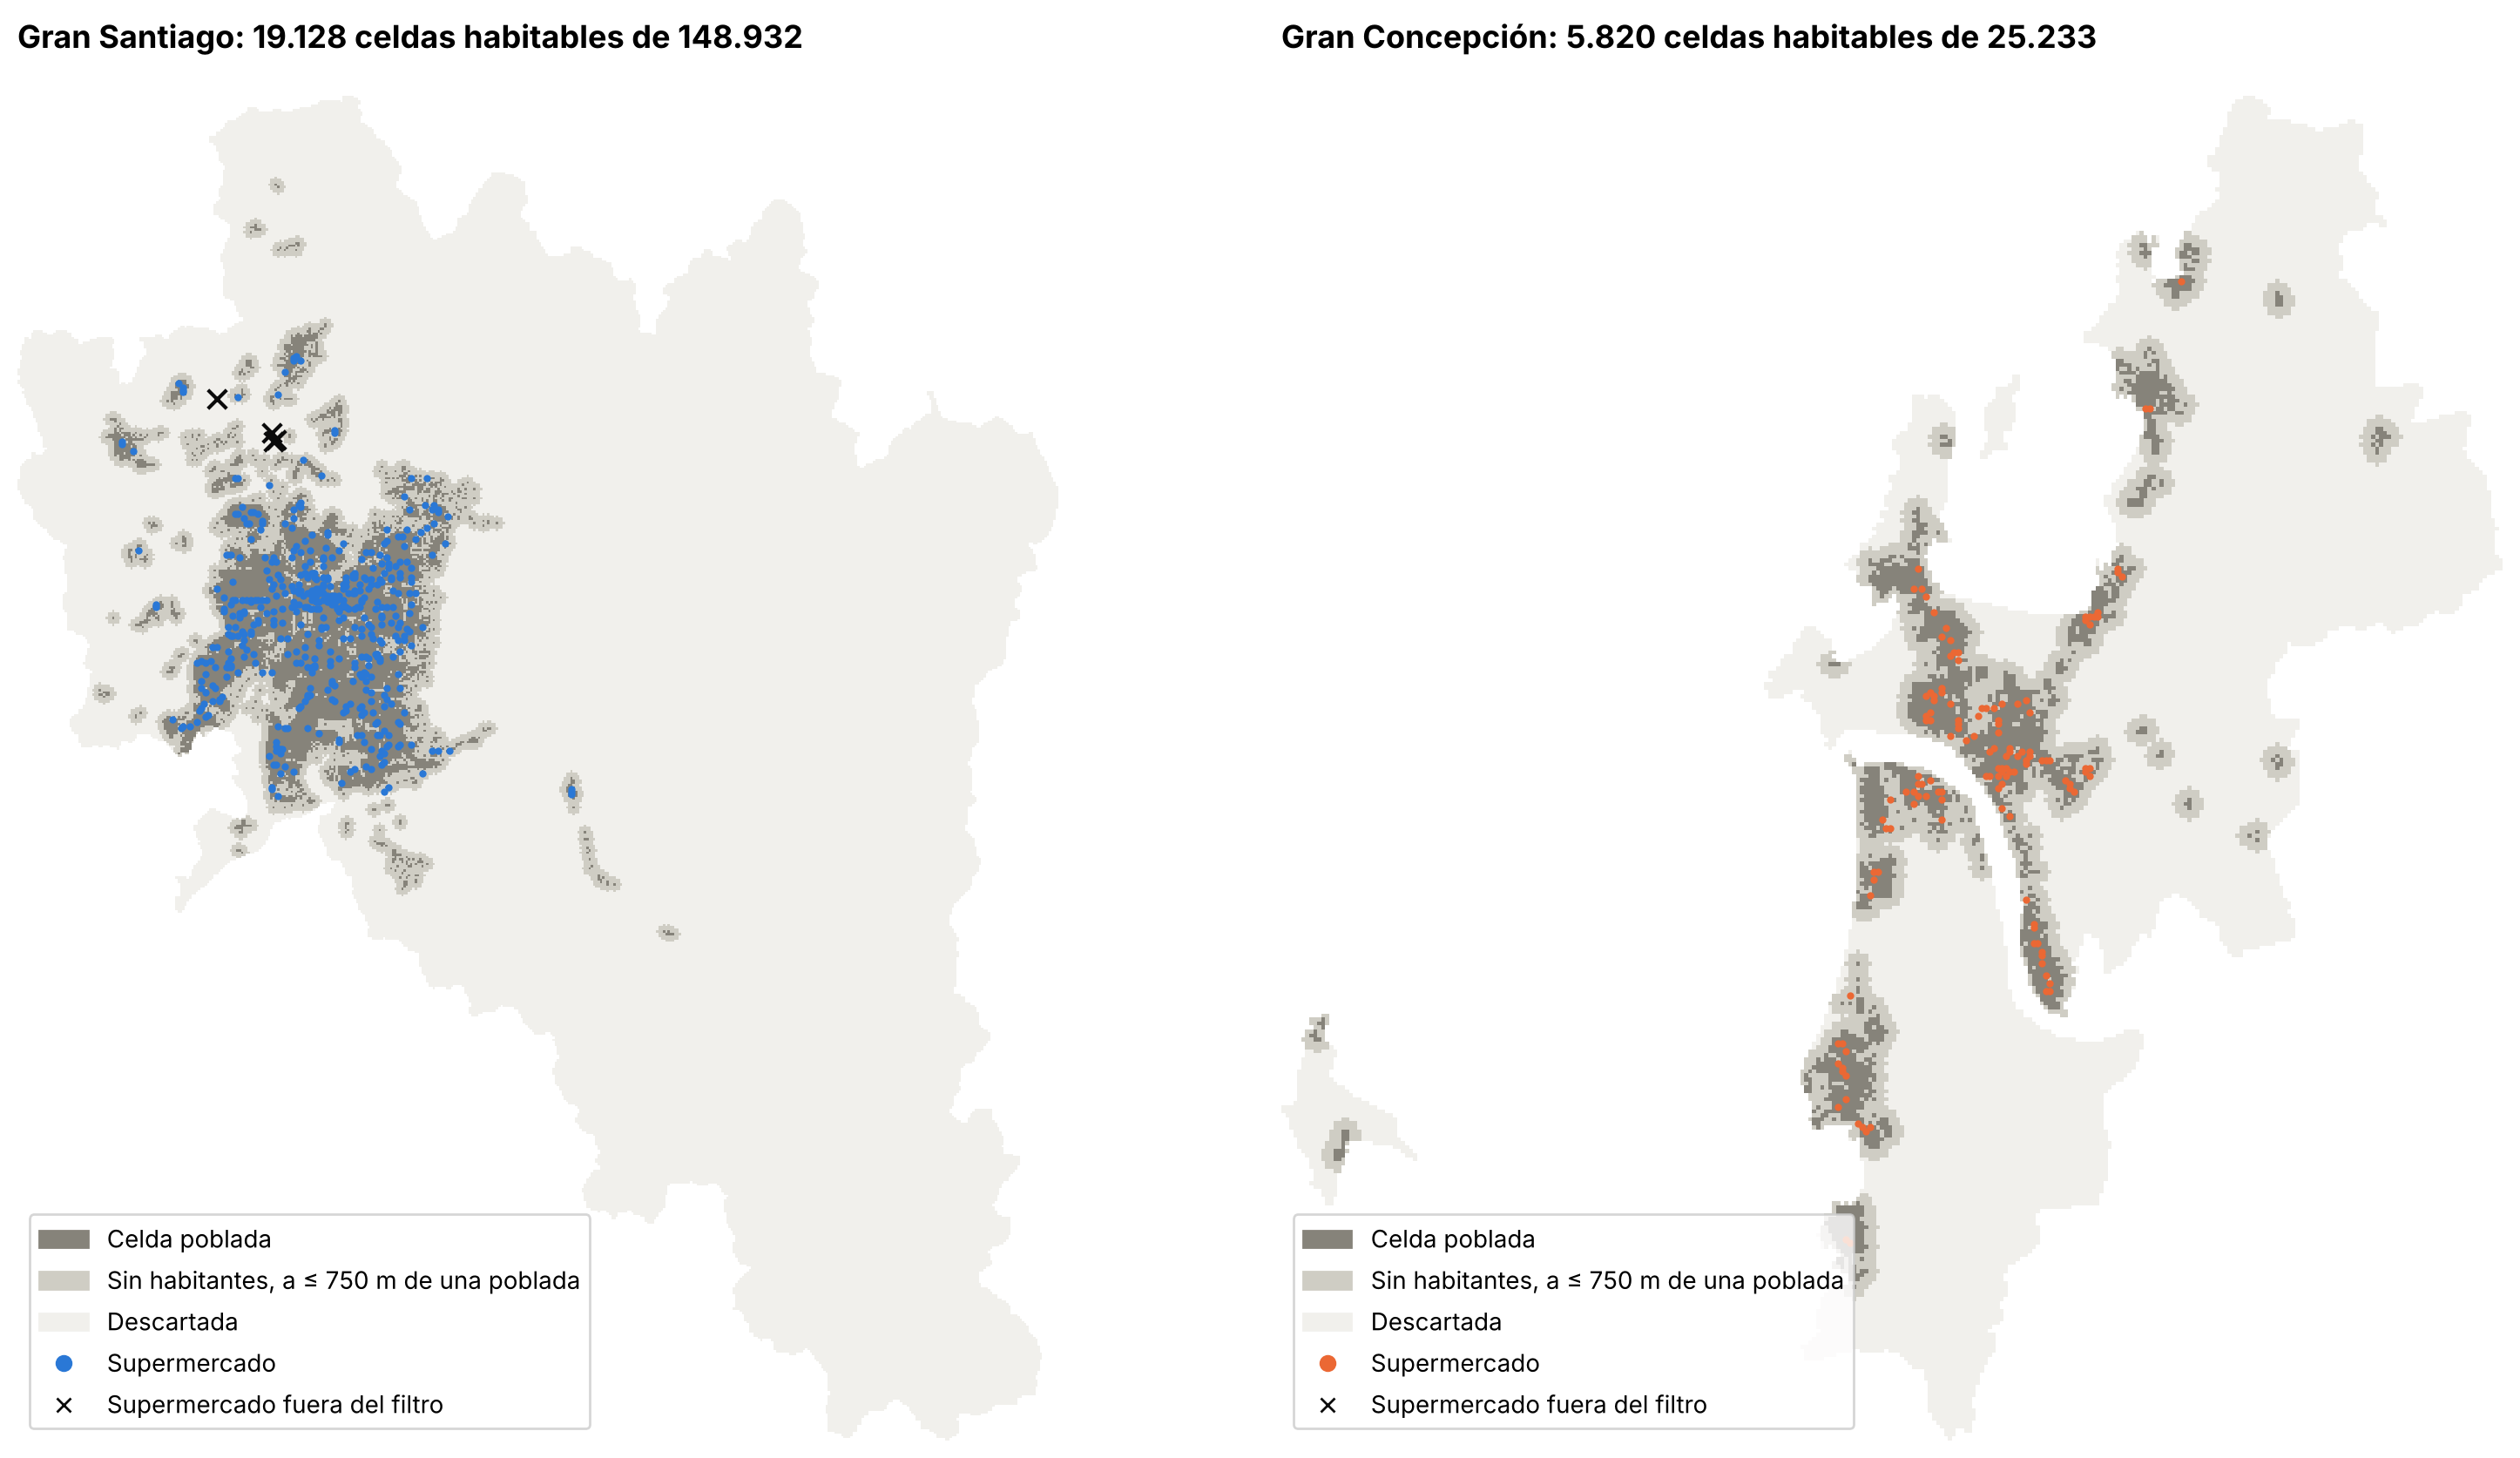

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 8.5))
fondo = ListedColormap(["#ffffff", "#f1f0ec", "#cfcdc4", "#86837a"])
for ciudad, ax in zip(cfg["ciudades"], ejes):
    t = features.agregar_variables(pd.read_parquet(f"{procesados}/celdas_{ciudad}_250m.parquet"), cfg)
    t["habitable"] = t["dist_poblada_m"] <= x + 1e-6
    s = float(t["tamano_m"].iloc[0])
    x0 = (t["x"] - (t["ix"] + 0.5) * s).iloc[0]
    y0 = (t["y"] - (t["iy"] + 0.5) * s).iloc[0]
    clase = np.where(t["poblacion_celda"] > 0, 3, np.where(t["habitable"], 2, 1))
    matriz = features.a_matriz(t, clase)
    ax.imshow(matriz, origin="lower", cmap=fondo, vmin=0, vmax=3, interpolation="nearest",
              extent=[x0, x0 + matriz.shape[1] * s, y0, y0 + matriz.shape[0] * s])
    dentro = t[t["habitable"] & (t["n_supermercados"] > 0)]
    fuera = t[~t["habitable"] & (t["n_supermercados"] > 0)]
    ax.scatter(dentro["x"], dentro["y"], s=9, color=COLORES[ciudad], linewidths=0)
    ax.scatter(fuera["x"], fuera["y"], s=60, marker="x", color="#0b0b0b", linewidths=1.5)
    ax.set_title(f"{NOMBRES[ciudad]}: {t['habitable'].sum():,} celdas habitables de {len(t):,}".replace(",", "."))
    ax.set_axis_off()
    ax.legend(handles=[
        Patch(color="#86837a", label="Celda poblada"),
        Patch(color="#cfcdc4", label=f"Sin habitantes, a ≤ {x:.0f} m de una poblada"),
        Patch(color="#f1f0ec", label="Descartada"),
        Line2D([], [], marker="o", linestyle="", color=COLORES[ciudad], label="Supermercado"),
        Line2D([], [], marker="x", linestyle="", color="#0b0b0b", label="Supermercado fuera del filtro"),
    ], loc="lower left", frameon=True, fontsize=10)
fig.tight_layout()
fig.savefig(f"{resultados}/mapa_filtro_250m.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 4. Efecto del filtro en cada tamaño de celda

El mismo X se aplica a todos los tamaños. `pct_celdas_habitables_con_super` es la proporción de celdas con al menos un supermercado dentro del universo que usará el modelo.

In [5]:
resumen.set_index(["ciudad", "tamano_m", "desfase_m"])

,,,celdas,celdas_habitables,pct_celdas_habitables,supermercados,supermercados_conservados,pct_supermercados_conservados,pct_celdas_habitables_con_super
ciudad,tamano_m,desfase_m,,,,,,,
stgo,125,0.0,592306,75336,12.7,524,520,99.2,0.67
ccp,125,0.0,98542,22137,22.5,159,159,100.0,0.69
stgo,250,0.0,148932,19128,12.8,524,520,99.2,2.54
ccp,250,0.0,25233,5820,23.1,159,159,100.0,2.37
stgo,500,0.0,37661,4988,13.2,524,520,99.2,8.72
ccp,500,0.0,6580,1616,24.6,159,159,100.0,6.93
stgo,1000,0.0,9623,1065,11.1,524,519,99.0,30.61
ccp,1000,0.0,1783,338,19.0,159,159,100.0,23.67
stgo,250,125.0,148927,19083,12.8,524,520,99.2,2.54


## 5. ¿Aportan las variables de entorno?

Correlación de Spearman entre `n_supermercados` y cada variable, medida en la celda, en 500 m y en 1 km, solo en celdas habitables de 250 m. Es una mirada bivariada: el modelo decidirá cómo combinarlas.

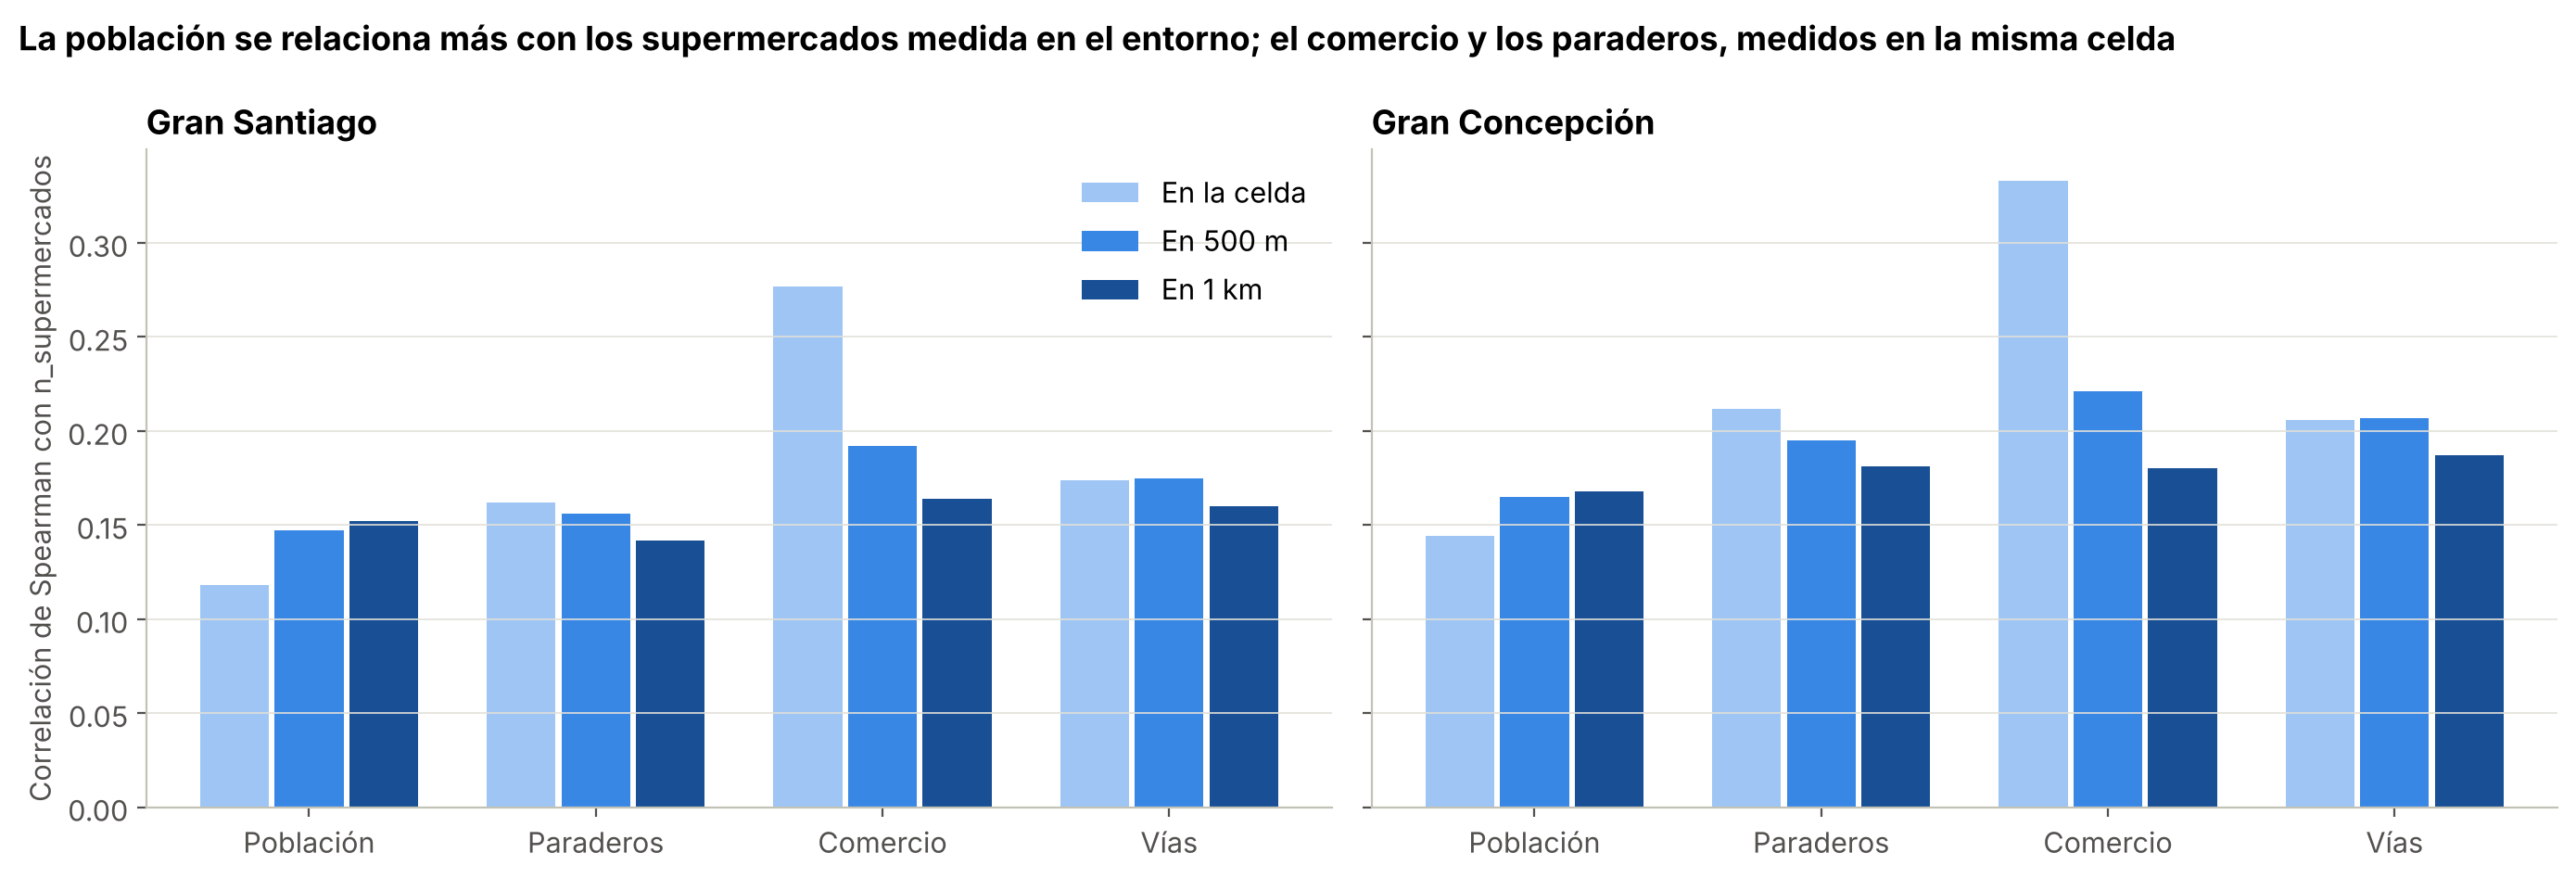

ciudad                  stgo    ccp
familia   escala                   
Población En la celda  0.118  0.144
          En 500 m     0.147  0.165
          En 1 km      0.152  0.168
Paraderos En la celda  0.162  0.212
          En 500 m     0.156  0.195
          En 1 km      0.142  0.181
Comercio  En la celda  0.277  0.333
          En 500 m     0.192  0.221
          En 1 km      0.164  0.180
Vías      En la celda  0.174  0.206
          En 500 m     0.175  0.207
          En 1 km      0.160  0.187

In [6]:
m = pd.read_parquet(f"{procesados}/modelo_250m.parquet")
comercio = cfg["features"]["grupos_poi"]["comercio"]
m["comercio_celda"] = m[[f"conteo_{k}" for k in comercio]].sum(axis=1)
familias = {
    "Población": ["poblacion_celda", "pob_500m", "pob_1000m"],
    "Paraderos": ["conteo_paraderos", "paraderos_500m", "paraderos_1000m"],
    "Comercio": ["comercio_celda", "comercio_500m", "comercio_1000m"],
    "Vías": ["largo_vias_m", "vias_km_500m", "vias_km_1000m"],
}
escalas = ["En la celda", "En 500 m", "En 1 km"]
tonos = ["#9ec5f4", "#3987e5", "#184f95"]

filas = []
for ciudad, d in m.groupby("ciudad"):
    for familia, columnas in familias.items():
        for escala, col in zip(escalas, columnas):
            filas.append({"ciudad": ciudad, "familia": familia, "escala": escala, "variable": col,
                          "spearman": round(d["n_supermercados"].corr(d[col], method="spearman"), 3)})
corr = pd.DataFrame(filas)
corr.to_csv(f"{resultados}/correlaciones_entorno_250m.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ancho = 0.26
for ciudad, ax in zip(["stgo", "ccp"], ejes):
    d = corr[corr["ciudad"] == ciudad]
    for i, (escala, tono) in enumerate(zip(escalas, tonos)):
        valores = d[d["escala"] == escala].set_index("familia").loc[list(familias), "spearman"]
        ax.bar(np.arange(len(familias)) + (i - 1) * ancho, valores, width=ancho - 0.02, color=tono, label=escala)
    ax.set_xticks(np.arange(len(familias)), list(familias))
    ax.set_title(NOMBRES[ciudad])
    ax.axhline(0, color="#c3c2b7", linewidth=1)
    ax.grid(axis="x", visible=False)
ejes[0].set_ylabel("Correlación de Spearman con n_supermercados")
ejes[0].legend(frameon=False, loc="upper right")
fig.suptitle("La población se relaciona más con los supermercados medida en el entorno; "
             "el comercio y los paraderos, medidos en la misma celda", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{resultados}/correlaciones_entorno_250m.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

orden = pd.MultiIndex.from_product([list(familias), escalas], names=["familia", "escala"])
corr.pivot_table(index=["familia", "escala"], columns="ciudad", values="spearman").reindex(orden)[["stgo", "ccp"]]

## 6. Variables para el modelo

`columnas_predictoras` deja fuera los identificadores, la ubicación (`x`, `y`, `ix`, `iy`) y las variables de competencia (`n_super_500m`, `n_super_1000m`, `dist_super_m`). Estas últimas son la variable objetivo desplazada en el espacio: si el modelo las usara, recomendaría abrir supermercados al lado de los que ya existen. Se guardan para la capa de decisión (por ejemplo, descartar zonas con un supermercado a menos de 500 m).

In [7]:
predictoras = features.columnas_predictoras(m.drop(columns="comercio_celda"), cfg)
print(f"{len(predictoras)} variables predictoras:")
print(", ".join(predictoras))
print()
print("Promedio y varianza de n_supermercados por ciudad (sobredispersión si la varianza es mucho mayor):")
m.groupby("ciudad")["n_supermercados"].agg(["mean", "var"]).round(4)

33 variables predictoras:
conteo_paraderos, conteo_convenience, conteo_mall, conteo_pharmacy, conteo_marketplace, conteo_school, conteo_university, conteo_college, conteo_hospital, conteo_clinic, conteo_sports_centre, poblacion_celda, largo_vias_m, dist_via_principal_m, frac_residencial, dist_poblada_m, dist_paradero_m, pob_500m, paraderos_500m, comercio_500m, educacion_500m, salud_500m, deporte_500m, vias_km_500m, residencial_500m, pob_1000m, paraderos_1000m, comercio_1000m, educacion_1000m, salud_1000m, deporte_1000m, vias_km_1000m, residencial_1000m

Promedio y varianza de n_supermercados por ciudad (sobredispersión si la varianza es mucho mayor):


,mean,var
ciudad,,
ccp,0.0273,0.0355
stgo,0.0272,0.0309


## 7. Diccionario de las variables nuevas

| Columna | Descripción |
| --- | --- |
| `dist_poblada_m` | Distancia del centro de la celda al centro de la celda poblada más cercana (0 si la celda tiene habitantes) |
| `dist_paradero_m` | Distancia a la celda más cercana con un paradero o estación |
| `pob_500m`, `pob_1000m` | Habitantes en las celdas cuyo centro está a 500 m o 1 km o menos (incluye la propia celda) |
| `paraderos_<radio>` | Paraderos y estaciones en el radio |
| `comercio_<radio>` | Almacenes, malls, farmacias y ferias en el radio |
| `educacion_<radio>` | Colegios, universidades e institutos en el radio |
| `salud_<radio>` | Hospitales y clínicas en el radio |
| `deporte_<radio>` | Recintos deportivos en el radio |
| `vias_km_<radio>` | Kilómetros de vías principales y secundarias en el radio |
| `residencial_<radio>` | Fracción residencial promedio de las celdas del radio |
| `n_super_500m`, `n_super_1000m` | Supermercados en el radio, incluida la celda. **Solo para la capa de decisión** |
| `dist_super_m` | Distancia a la celda más cercana con supermercado (0 si la celda tiene uno). **Solo para la capa de decisión** |

Los radios se miden entre centros de celda, así que a 1000 m de celda el radio de 500 m solo incluye la propia celda.